# PyCUDA and cuSPARSE: sparse matrix products

Start with a tridiagonal matrix in compressed sparse row (CSR) form. Compute $y=Ax$, then $Y=AX$ for several vectors at once, and finally $S=AA$ without converting the full matrix to dense storage. Check every result with SciPy.

Run cells in order in a Google Colab GPU runtime. All figures and printouts stay in the notebook; no result files are exported. This is an introductory correctness experiment, not a CPU/GPU speed benchmark.

PyCUDA owns the GPU arrays and transfers; **cuSPARSE**, called through NVIDIA `nvmath.bindings`, performs the numerical operation. These bindings are a separate package, not part of PyCUDA. The examples do not call CuPy.

## 1. Prepare a fresh Google Colab GPU runtime

Choose **Runtime → Change runtime type → GPU**. Run the setup before imports. It installs PyCUDA and pins nvmath-python 1.0.0, with the CUDA 12 or 13 dependencies matching the runtime toolkit. Installation can take several minutes. A compatible NVIDIA driver and `nvcc` are still required. The low-level bindings are documented as experimental, so the package version is fixed rather than silently taking an arbitrary future release.

Use a fresh runtime for this notebook; do not mix `pycuda.autoinit` from an earlier notebook with the primary-context initialization used here.

In [1]:
import re
import subprocess
import sys
from importlib.metadata import version, PackageNotFoundError

# Run this cell before importing PyCUDA or nvmath in a fresh GPU runtime.
subprocess.run(["nvidia-smi"], check=True)
info = subprocess.check_output(["nvcc", "--version"], text=True)
print(info)
match = re.search(r"release\s+(\d+)\.", info)
if not match or int(match.group(1)) not in (12, 13):
    raise RuntimeError("This notebook setup targets CUDA 12 or 13.")
major = int(match.group(1))
requirements = ["pycuda", f"nvmath-python[cu{major}]==1.0.0"]
subprocess.check_call([sys.executable, "-m", "pip", "install", *requirements])
print("Setup complete. If Colab asks for a runtime restart, restart before proceeding.")

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2025 NVIDIA Corporation
Built on Wed_Aug_20_01:58:59_PM_PDT_2025
Cuda compilation tools, release 13.0, V13.0.88
Build cuda_13.0.r13.0/compiler.36424714_0

Setup complete. If Colab asks for a runtime restart, restart before proceeding.


## 2. Imports and validation

The primary CUDA context is shared by the PyCUDA allocations and library calls. All work uses the default stream; the examples wait for completion before destroying library resources. Double precision and the same input formulas as in the CuPy notebook permit like-for-like correctness checks.

In [2]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import pycuda.driver as cuda
import pycuda.autoprimaryctx  # keep one primary context current for these libraries
import pycuda.gpuarray as gpuarray
import nvmath
from importlib.metadata import version

print("GPU:", cuda.Context.get_device().name())
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__, "PyCUDA:", version("pycuda"),
      "nvmath-python:", version("nvmath-python"))
plt.rcParams.update({'figure.dpi':120, 'font.size':11,
                     'axes.spines.top':False, 'axes.spines.right':False})

def ptr(a):
    # The owner must remain alive while the library uses its device storage.
    return int(a.gpudata)

import scipy.sparse as sp

GPU: Tesla T4
Python: 3.13.15
NumPy: 2.1.3 PyCUDA: 2026.1 nvmath-python: 1.0.0


In [3]:
def check(label, result, reference, rtol=1e-11, atol=1e-11):
    assert result.shape == reference.shape, (result.shape, reference.shape)
    assert result.dtype == reference.dtype, (result.dtype, reference.dtype)
    if not np.all(np.isfinite(result)):
        raise AssertionError(f"{label}: nonfinite result")
    np.testing.assert_allclose(result, reference, rtol=rtol, atol=atol)
    error = np.max(np.abs(result-reference))
    relative = np.linalg.norm((result-reference).ravel()) / max(np.linalg.norm(reference.ravel()), np.finfo(float).tiny)
    print(f"{label}: validated; max absolute error={error:.3e}; relative norm error={relative:.3e}")

### Library bridge: CSR descriptors and products

Run this support cell once; its implementation can be revisited later. `DeviceCSR`, `sparse_product_gpu` and `sparse_square_gpu` are helpers supplied with this notebook, **not PyCUDA classes or functions**. They allocate CSR arrays with PyCUDA and call cuSPARSE via nvmath bindings. The SpMV, SpMM and SpGEMM numerical algorithms are provided by cuSPARSE.

A descriptor describes existing device storage; it does not copy or own the values. Workspaces hold library scratch data. The helpers retain these objects until execution finishes. For sparse–sparse multiplication, an initial phase determines the output size before its column/value arrays can be allocated. This extra bookkeeping is normally hidden by CuPy.

In [4]:
from contextlib import ExitStack
from nvmath.bindings import cusparse
from nvmath import CudaDataType

F64 = CudaDataType.CUDA_R_64F
I32 = cusparse.IndexType.INDEX_32I
OP = cusparse.Operation.NON_TRANSPOSE

class DeviceCSR:
    """Own CSR arrays on the GPU; descriptors are temporary non-owning views."""
    def __init__(self, matrix):
        matrix = matrix.tocsr(copy=True).astype(np.float64)
        matrix.sum_duplicates()
        matrix.sort_indices()
        if max(*matrix.shape, matrix.nnz) > np.iinfo(np.int32).max:
            raise ValueError("This teaching wrapper uses 32-bit CSR indices")
        self.shape, self.nnz = matrix.shape, matrix.nnz
        self.data = gpuarray.to_gpu(matrix.data)
        self.indices = gpuarray.to_gpu(matrix.indices.astype(np.int32))
        self.indptr = gpuarray.to_gpu(matrix.indptr.astype(np.int32))

    def descriptor(self):
        return cusparse.create_csr(*self.shape, self.nnz,
            ptr(self.indptr), ptr(self.indices), ptr(self.data),
            I32, I32, cusparse.IndexBase.ZERO, F64)

    def get(self):
        return sp.csr_matrix((self.data.get(), self.indices.get(), self.indptr.get()),
                             shape=self.shape)

def sparse_product_gpu(a, x):
    """CSR x dense vector (SpMV) or dense matrix (SpMM), float64."""
    if len(x.shape) not in (1, 2) or x.shape[0] != a.shape[1]:
        raise ValueError("Incompatible dimensions")
    if x.dtype != np.float64 or not x.flags.c_contiguous:
        raise ValueError("Expected a C-contiguous float64 dense operand")
    shape = (a.shape[0],) if len(x.shape) == 1 else (a.shape[0], x.shape[1])
    y = gpuarray.empty(shape, np.float64)
    alpha, beta = np.array(1., np.float64), np.array(0., np.float64)
    with ExitStack() as release:
        handle = cusparse.create()
        release.callback(cusparse.destroy, handle)
        cusparse.set_pointer_mode(handle, cusparse.PointerMode.HOST)
        cusparse.set_stream(handle, 0)
        da = a.descriptor()
        release.callback(cusparse.destroy_sp_mat, da)
        if len(x.shape) == 1:
            dx = cusparse.create_dn_vec(x.size, ptr(x), F64)
            release.callback(cusparse.destroy_dn_vec, dx)
            dy = cusparse.create_dn_vec(y.size, ptr(y), F64)
            release.callback(cusparse.destroy_dn_vec, dy)
            args = (handle, OP, alpha.ctypes.data, da, dx,
                    beta.ctypes.data, dy, F64, cusparse.SpMVAlg.DEFAULT)
            size = cusparse.sp_mv_buffer_size(*args)
            workspace = cuda.mem_alloc(max(1, size))
            cusparse.sp_mv(*args, int(workspace))
        else:
            # Explicit ROW order avoids changing the NumPy/CuPy layout.
            dx = cusparse.create_dn_mat(*x.shape, x.shape[1], ptr(x), F64, cusparse.Order.ROW)
            release.callback(cusparse.destroy_dn_mat, dx)
            dy = cusparse.create_dn_mat(*y.shape, y.shape[1], ptr(y), F64, cusparse.Order.ROW)
            release.callback(cusparse.destroy_dn_mat, dy)
            args = (handle, OP, OP, alpha.ctypes.data, da, dx,
                    beta.ctypes.data, dy, F64, cusparse.SpMMAlg.DEFAULT)
            size = cusparse.sp_mm_buffer_size(*args)
            workspace = cuda.mem_alloc(max(1, size))
            cusparse.sp_mm(*args, int(workspace))
        # Keep workspace, arrays and host scalars alive until completion.
        cuda.Context.synchronize()
    return y

def sparse_square_gpu(a):
    """Form an explicit CSR A*A using the cuSPARSE SpGEMM protocol."""
    if a.shape[0] != a.shape[1]:
        raise ValueError("A must be square")
    n = a.shape[0]
    alpha, beta = np.array(1., np.float64), np.array(0., np.float64)
    row_c = gpuarray.empty(n+1, np.int32)
    with ExitStack() as release:
        handle = cusparse.create()
        release.callback(cusparse.destroy, handle)
        cusparse.set_pointer_mode(handle, cusparse.PointerMode.HOST)
        cusparse.set_stream(handle, 0)
        da = a.descriptor()
        release.callback(cusparse.destroy_sp_mat, da)
        db = a.descriptor()  # same input storage; independent descriptors
        release.callback(cusparse.destroy_sp_mat, db)
        dc = cusparse.create_csr(n, n, 0, ptr(row_c), 0, 0,
                                 I32, I32, cusparse.IndexBase.ZERO, F64)
        release.callback(cusparse.destroy_sp_mat, dc)
        product = cusparse.sp_gemm_create_descr()
        release.callback(cusparse.sp_gemm_destroy_descr, product)
        args = (handle, OP, OP, alpha.ctypes.data, da, db,
                beta.ctypes.data, dc, F64, cusparse.SpGEMMAlg.DEFAULT, product)
        size1 = cusparse.sp_gemm_work_estimation(*args, 0)
        work1 = cuda.mem_alloc(max(1, size1))
        cusparse.sp_gemm_work_estimation(*args, int(work1))
        # This binding takes a host size_t* for the in/out buffer-size value.
        size2 = np.zeros(1, dtype=np.uintp)
        cusparse.sp_gemm_compute(*args, size2.ctypes.data, 0)
        work2 = cuda.mem_alloc(max(1, int(size2[0])))
        cusparse.sp_gemm_compute(*args, size2.ctypes.data, int(work2))
        cuda.Context.synchronize()
        rows, cols, nnz = cusparse.sp_mat_get_size(dc)
        col_c = gpuarray.empty(int(nnz), np.int32)
        val_c = gpuarray.empty(int(nnz), np.float64)
        cusparse.csr_set_pointers(dc, ptr(row_c), ptr(col_c), ptr(val_c))
        cusparse.sp_gemm_copy(*args)
        cuda.Context.synchronize()
    result = DeviceCSR.__new__(DeviceCSR)
    result.shape, result.nnz = (int(rows), int(cols)), int(nnz)
    result.indptr, result.indices, result.data = row_c, col_c, val_c
    return result

## 3. Construct a sparse matrix directly

A has diagonal 2 and adjacent diagonals -1, with no periodic wraparound. It has $3N-2$ nonzero entries, compared with $N^2$ locations in dense storage. We use it only as a transparent algebraic example; no differential equation or boundary-value problem is being solved.

CSR stores nonzero values (`data`), their column indices (`indices`), and row boundaries in those arrays (`indptr`). The memory printout counts these arrays, not Python metadata or CUDA-library workspace.

In [5]:
N = 4096
assert N >= 3
A_cpu = sp.diags((-np.ones(N-1),2*np.ones(N),-np.ones(N-1)),
                 offsets=(-1,0,1),shape=(N,N),format='csr',dtype=np.float64)
A_cpu.sort_indices()
assert A_cpu.nnz == 3*N-2
index = np.arange(N,dtype=np.float64)
h_x = 0.3 + np.sin(0.03*index) + 0.1*np.cos(0.17*index)
y_cpu = A_cpu @ h_x
# Independent algebraic reference, including the first and last rows.
y_formula = 2*h_x.copy()
y_formula[1:] -= h_x[:-1]
y_formula[:-1] -= h_x[1:]
check("SciPy product vs explicit formula", y_cpu,y_formula)
csr_bytes=A_cpu.data.nbytes+A_cpu.indices.nbytes+A_cpu.indptr.nbytes
dense_bytes=N*N*np.dtype(np.float64).itemsize
print(f"Shape: {A_cpu.shape}; nonzeros: {A_cpu.nnz}; density: {A_cpu.nnz/(N*N):.6%}")
print(f"CSR array storage: {csr_bytes/1024:.1f} KiB")
print(f"Hypothetical dense storage: {dense_bytes/2**20:.1f} MiB (not allocated)")
print("First three CSR rows (column, value):")
for row in range(3):
    lo,hi=A_cpu.indptr[row:row+2]
    print(row,list(zip(A_cpu.indices[lo:hi].tolist(),A_cpu.data[lo:hi].tolist())))

SciPy product vs explicit formula: validated; max absolute error=0.000e+00; relative norm error=0.000e+00
Shape: (4096, 4096); nonzeros: 12286; density: 0.073230%
CSR array storage: 160.0 KiB
Hypothetical dense storage: 128.0 MiB (not allocated)
First three CSR rows (column, value):
0 [(0, 2.0), (1, -1.0)]
1 [(0, -1.0), (1, 2.0), (2, -1.0)]
2 [(1, -1.0), (2, 2.0), (3, -1.0)]


## 4. Transfer CSR storage and multiply by a vector

`DeviceCSR` copies the nonzero values, column indices and row offsets into three PyCUDA GPUArrays. `sparse_product_gpu` describes these arrays to cuSPARSE and calls its sparse matrix–vector routine. The full matrix is never expanded to dense storage. The result is retrieved with `.get()` and checked at every entry, including both boundaries.

In [6]:
A_gpu = DeviceCSR(A_cpu)
d_x = gpuarray.to_gpu(h_x)
d_y = sparse_product_gpu(A_gpu, d_x)
y_gpu = d_y.get()
check("Sparse matrix-vector product",y_gpu,y_cpu)
check("Sparse product vs explicit formula",y_gpu,y_formula)
print("Output class:",type(d_y).__name__,"shape:",d_y.shape)
selected=np.unique(np.r_[np.arange(5),N//2,np.arange(N-3,N)])
print(f"{'row':>7} {'GPU result':>20} {'SciPy result':>20}")
for i in selected:print(f"{i:7d} {y_gpu[i]:20.12f} {y_cpu[i]:20.12f}")

Sparse matrix-vector product: validated; max absolute error=1.110e-16; relative norm error=2.105e-15
Sparse product vs explicit formula: validated; max absolute error=1.110e-16; relative norm error=2.105e-15
Output class: GPUArray shape: (4096,)
    row           GPU result         SciPy result
      0       0.371446023107       0.371446023107
      1       0.002868480755       0.002868480755
      2       0.002771969209       0.002771969209
      3       0.002597047729       0.002597047729
      4       0.002349511303       0.002349511303
   2048      -0.003333150279      -0.003333150279
   4093      -0.000390282410      -0.000390282410
   4094       0.000073067422       0.000073067422
   4095      -0.005622320419      -0.005622320419


## 5. Apply the same sparse matrix to several columns

X contains three vectors. The product Y=AX applies A to every column and returns a dense matrix. Each column is checked with SciPy. This illustrates a sparse-matrix/dense-matrix product without introducing a solver.

In [7]:
h_X=np.column_stack((h_x,np.cos(0.05*index),index/(N-1))).astype(np.float64)
d_X=gpuarray.to_gpu(h_X)
d_Y=sparse_product_gpu(A_gpu, d_X)
Y_gpu=d_Y.get()
Y_cpu=A_cpu @ h_X
check("Sparse matrix-dense matrix product",Y_gpu,Y_cpu)
print("A:",A_gpu.shape,"X:",d_X.shape,"Y:",d_Y.shape)

Sparse matrix-dense matrix product: validated; max absolute error=2.220e-16; relative norm error=3.966e-16
A: (4096, 4096) X: (4096, 3) Y: (4096, 3)


## 6. Multiply two sparse matrices

S=AA is still stored sparsely, but generally has more nonzeros. Here the tridiagonal matrix produces a matrix with five diagonals. Sparse products do not guarantee that sparsity will remain low in a general problem.

Retrieve S with its `.get()` method, which returns a SciPy sparse matrix. Validation subtracts sparse matrices and checks their nonzero differences, avoiding a dense N-by-N allocation.

In [8]:
S_gpu=sparse_square_gpu(A_gpu)
S_host=S_gpu.get().tocsr()
S_cpu=(A_cpu @ A_cpu).tocsr()
assert S_host.shape==S_cpu.shape and S_host.dtype==S_cpu.dtype
assert np.all(np.isfinite(S_host.data))
difference=(S_host-S_cpu).tocsr()
difference.eliminate_zeros()
max_sparse_error=np.max(np.abs(difference.data)) if difference.nnz else 0.0
assert max_sparse_error <= 1e-11
S_host.eliminate_zeros()
assert S_host.nnz==S_cpu.nnz==5*N-6
print(f"A nonzeros: {A_cpu.nnz}; A @ A nonzeros: {S_host.nnz}")
print(f"Sparse-sparse product validated; maximum absolute error: {max_sparse_error:.3e}")

A nonzeros: 12286; A @ A nonzeros: 20474
Sparse-sparse product validated; maximum absolute error: 0.000e+00


## 7. Show sparsity and numerical output

Only small leading blocks are plotted as sparsity patterns. The full matrices remain sparse. The curve shows an interior portion of Ax; boundary rows are included in validation and in the earlier printout.

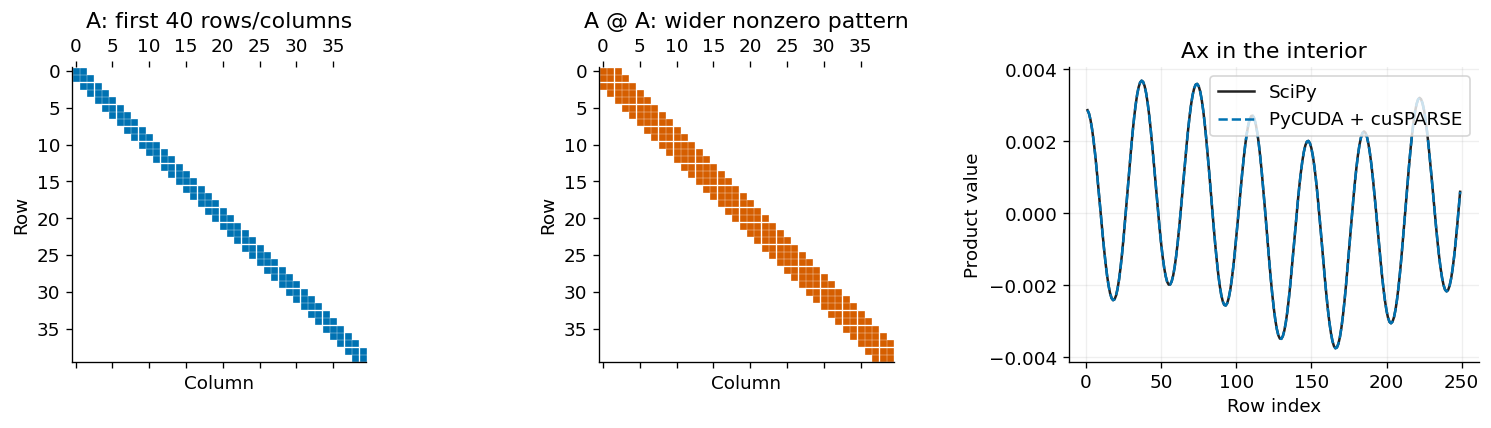

In [9]:
fig,axes=plt.subplots(1,3,figsize=(13,3.7))
preview=40
axes[0].spy(A_cpu[:preview,:preview],markersize=3,color='#0072B2')
axes[0].set(title='A: first 40 rows/columns',xlabel='Column',ylabel='Row')
axes[1].spy(S_host[:preview,:preview],markersize=3,color='#D55E00')
axes[1].set(title='A @ A: wider nonzero pattern',xlabel='Column',ylabel='Row')
indices=np.arange(1,min(250,N-1))
axes[2].plot(indices,y_cpu[indices],color='#222222',label='SciPy')
axes[2].plot(indices,y_gpu[indices],'--',color='#0072B2',label='PyCUDA + cuSPARSE')
axes[2].set(xlabel='Row index',ylabel='Product value',title='Ax in the interior')
axes[2].legend();axes[2].grid(alpha=.2)
fig.tight_layout();plt.show()

## Interpretation and execution status

The arrays are owned by PyCUDA; the numerical operation is executed by the named NVIDIA library through nvmath bindings. Plan creation, handles, descriptors, and workspaces are explicit here, whereas CuPy normally manages them behind its array interface. These teaching helpers deliberately synchronize before releasing resources; they are not benchmark harnesses or optimized repeated-operation wrappers. A production solver would reuse compatible plans, handles, buffers and descriptors.

**Preparation status:** code syntax, CPU reference calculations, data-layout checks and plotting logic were checked. GPU execution and Colab package installation could not be tested in the preparation environment. No GPU outputs or timings are prefilled.

References: [PyCUDA GPUArray](https://documen.tician.de/pycuda/array.html), [NVIDIA nvmath bindings](https://docs.nvidia.com/cuda/nvmath-python/latest/bindings/index.html), [installation](https://docs.nvidia.com/cuda/nvmath-python/latest/installation.html).

## Cleanup

Library handles and descriptors are released by the helper functions after completion. Remove the remaining device arrays below. To repeat the experiment, rerun from data preparation.

In [10]:
cuda.Context.synchronize()
del A_gpu, d_x, d_y, d_X, d_Y, S_gpu
print("Device array references released.")

Device array references released.
